In [20]:
import json, random, sys
from collections import Counter, defaultdict
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import cv2

PROJECT_ROOT = Path.cwd().parent         
sys.path.insert(0, str(PROJECT_ROOT))

import utils.sunrgbd as sd

In [7]:
DATASET_ROOT = Path("/Users/polina_sushko/My_work/University/ВКР/SUNRGBD")
OUT_DIR      = Path("outputs")

TOP_K_CLASSES                     = 10 # скільки найчастотніших категорій залишити
VAL_FRACTION, TEST_FRACTION, SEED = 0.15, 0.15, 42 # частки вибірок і зерно генератора (для відтворюваності)
MIN_MASK_AREA, MIN_BBOX_SIDE      = 200.0, 8.0 # Фільтри дрібних об'єкті
REQUIRE_INTRINSICS                = True # Залишати лише сцени з параметрами камери (потрібні для 3D у розділі 3)

OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Набір даних:", DATASET_ROOT)
print("Існує:", DATASET_ROOT.is_dir())

Набір даних: /Users/polina_sushko/My_work/University/ВКР/SUNRGBD
Існує: True


---
## Сканування набору даних

In [ ]:
scenes = sd.find_scenes(DATASET_ROOT, require_annotation = False)
print(f"Знайдено сцен: {len(scenes)}")

# групування кадрів для коректного поділу вибірок
sd.assign_groups(scenes)
print(f"Унікальних груп сцен: {len({s.group_key for s in scenes})}")

Знайдено сцен: 10335
Унікальних груп сцен: 7954


In [10]:
rows = []
for i, s in enumerate(scenes, 1):
    if i % 500 == 0 or i == len(scenes):
        print(f"  оброблено {i}/{len(scenes)}", end="\r")
    intr = sd.read_intrinsics(s.intrinsics_path)
    anns = sd.load_annotations(s.annotation_path)
    rows.append({
        "rel_key": s.rel_key, "group_key": s.group_key,
        "sensor": s.sensor, "collection": s.collection, "scene_type": s.scene_type,
        "has_intrinsics": intr is not None,
        "fx": intr.fx if intr else None, "fy": intr.fy if intr else None,
        "cx": intr.cx if intr else None, "cy": intr.cy if intr else None,
        "n_objects": len(anns),
        "depth_source": getattr(s, "depth_source", ""),
    })
print()

scan_df = pd.DataFrame(rows)
scan_df.to_csv(OUT_DIR / "scenes_index.csv", index=False)

usable = scan_df[(scan_df.n_objects > 0) & scan_df.has_intrinsics]
print(f"Усього сцен:                {len(scan_df)}")
print(f"З анотаціями об'єктів:      {(scan_df.n_objects > 0).sum()}")
print(f"З параметрами камери:       {scan_df.has_intrinsics.sum()}")
print(f"Придатних до використання:  {len(usable)}")
print(f"Усього анотованих об'єктів: {scan_df.n_objects.sum()}")

display(scan_df.sensor.value_counts().to_frame("Кількість сцен"))
scan_df.head()

  оброблено 10335/10335
Усього сцен:                10335
З анотаціями об'єктів:      10295
З параметрами камери:       10335
Придатних до використання:  10295
Усього анотованих об'єктів: 173502


,Кількість сцен
sensor,
kv2,3784
xtion,3389
kv1,2003
realsense,1159


,rel_key,group_key,sensor,collection,scene_type,has_intrinsics,fx,fy,cx,cy,n_objects,depth_source
0,kv1/NYUdata/NYU0001,kv1/NYUdata/NYU0001,kv1,NYUdata,kitchen,True,518.857901,519.469611,284.582449,208.736166,26,depth_bfx
1,kv1/NYUdata/NYU0002,kv1/NYUdata/NYU0002,kv1,NYUdata,kitchen,True,518.857901,519.469611,284.582449,208.736166,28,depth_bfx
2,kv1/NYUdata/NYU0003,kv1/NYUdata/NYU0003,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,21,depth_bfx
3,kv1/NYUdata/NYU0004,kv1/NYUdata/NYU0004,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,24,depth_bfx
4,kv1/NYUdata/NYU0005,kv1/NYUdata/NYU0005,kv1,NYUdata,office,True,518.857901,519.469611,284.582449,208.736166,34,depth_bfx


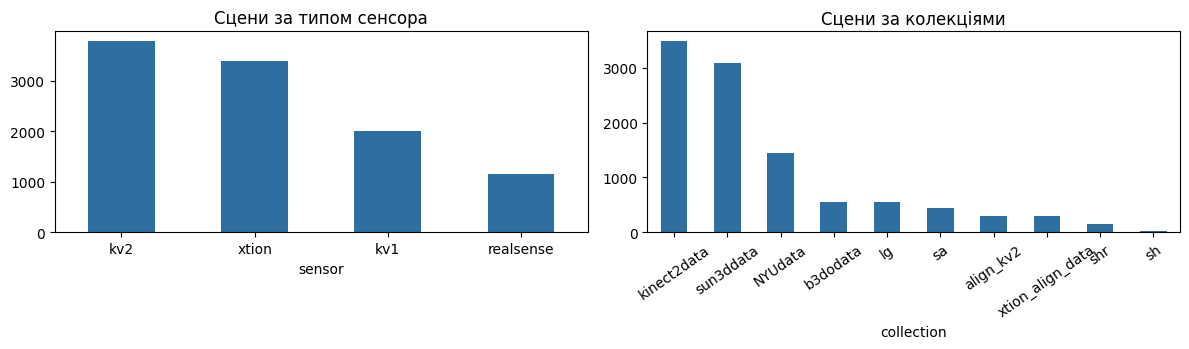

In [11]:
# розподіл сцен за сенсорами та колекціями
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
scan_df.sensor.value_counts().plot.bar(ax=axes[0], color="#2f6f9f")
axes[0].set_title("Сцени за типом сенсора"); axes[0].tick_params(axis="x", rotation=0)
scan_df.collection.value_counts().head(10).plot.bar(ax=axes[1], color="#2f6f9f")
axes[1].set_title("Сцени за колекціями"); axes[1].tick_params(axis="x", rotation=35)
plt.tight_layout(); plt.show()

### Параметри камери

У наборі використано чотири типи сенсорів, і фокусні відстані в них **різні**.
Саме тому параметри камери зчитуються для кожної сцени окремо.

fx                 fy                 cx                cy       \
            mean   std count   mean   std count   mean  std count   mean  std   
sensor                                                                          
kv1        519.3   0.7  2003  519.8   0.6  2003  282.7  3.0  2003  210.5  2.9   
kv2        529.5   0.0  3784  529.5   0.0  3784  365.0  0.0  3784  265.0  0.0   
realsense  693.7   0.3  1159  693.7   0.3  1159  360.5  0.3  1159  264.8  0.0   
xtion      567.0  10.7  3389  567.0  10.7  3389  308.3  5.4  3389  225.5  1.7   

                 
          count  
sensor           
kv1        2003  
kv2        3784  
realsense  1159  
xtion      3389

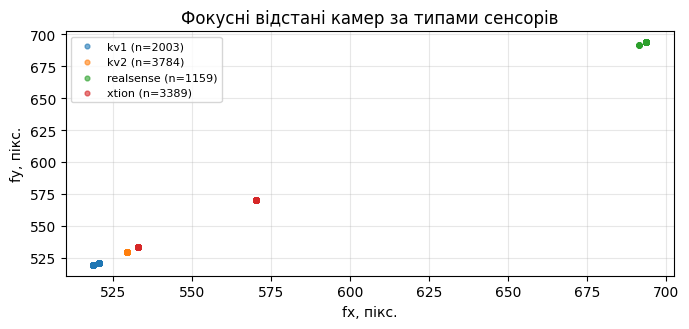

In [12]:
intr_df = scan_df[scan_df.has_intrinsics]
display(intr_df.groupby("sensor")[["fx", "fy", "cx", "cy"]].agg(["mean", "std", "count"]).round(1))

fig, ax = plt.subplots(figsize=(7, 3.4))
for sensor, grp in intr_df.groupby("sensor"):
    ax.scatter(grp.fx, grp.fy, s=12, alpha=0.6, label=f"{sensor} (n={len(grp)})")
ax.set_xlabel("fx, пікс."); ax.set_ylabel("fy, пікс.")
ax.set_title("Фокусні відстані камер за типами сенсорів")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

---
## Побудова COCO-анотацій

Перетворюємо анотації з `annotation2Dfinal/index.json` на стандартний формат COCO.

Виконується фільтрація:
* категорії **"stuff"** (стіна, підлога, стеля) виключаються — вони не є екземплярами об'єктів;
* відкидаються вироджені полігони (менше трьох точок) і занадто дрібні маски;
* **назви класів нормалізуються**: у наборі їх вводили вручну, тому трапляються
  `chair`, `Chair `, `chair2`, `chairs`. Без нормалізації один клас розпадається на десятки.

In [14]:
scenes_ann = [s for s in scenes if s.annotation_path is not None]
print(f"Сцен з файлами анотацій: {len(scenes_ann)}")

images, annotations = [], []
category_ids, category_counts = {}, Counter()
raw_to_norm, skipped = {}, Counter()
ann_id = 1

for img_id, scene in enumerate(scenes_ann, start=1):
    if img_id % 250 == 0 or img_id == len(scenes_ann):
        print(f"  оброблено {img_id}/{len(scenes_ann)}", end="\r")

    intr = sd.read_intrinsics(scene.intrinsics_path)
    if REQUIRE_INTRINSICS and intr is None:
        skipped["сцена без параметрів камери"] += 1
        continue
    try:
        with Image.open(scene.rgb_path) as im:
            width, height = im.size
    except OSError:
        skipped["не читається RGB"] += 1
        continue

    anns = sd.load_annotations(scene.annotation_path)
    if not anns:
        skipped["порожні анотації"] += 1
        continue

    kept = 0
    for obj in anns:
        raw_to_norm.setdefault(obj.raw_name.strip().lower(), obj.name)
        if not obj.name or obj.name in sd.STUFF_CLASSES:
            skipped["категорія stuff"] += 1
            continue

        polys = [sd.clip_polygon(p, width, height) for p in obj.polygons]
        polys = [p for p in polys if len(p) >= 6]
        if not polys:
            skipped["вироджений полігон"] += 1
            continue

        bbox, area = sd.polygons_bbox_area(polys, width, height)
        if area < MIN_MASK_AREA:
            skipped["замала площа маски"] += 1
            continue
        if bbox[2] < MIN_BBOX_SIDE or bbox[3] < MIN_BBOX_SIDE:
            skipped["замала обмежувальна рамка"] += 1
            continue

        category_ids.setdefault(obj.name, len(category_ids) + 1)
        category_counts[obj.name] += 1
        annotations.append({
            "id": ann_id, "image_id": img_id,
            "category_id": category_ids[obj.name],
            "segmentation": [[round(v, 2) for v in p] for p in polys],
            "bbox": [round(v, 2) for v in bbox], "area": round(area, 2),
            "iscrowd": 0,
        })
        ann_id += 1; kept += 1

    if kept == 0:
        skipped["сцена без придатних об'єктів"] += 1
        continue

    images.append({
        "id": img_id, "file_name": str(scene.rgb_path),
        "width": width, "height": height,
        # поля, потрібні для 3D-реконструкції
        "depth_file": str(scene.depth_path),
        "depth_source": getattr(scene, "depth_source", ""),
        "sensor": scene.sensor, "collection": scene.collection,
        "scene_type": scene.scene_type, "rel_key": scene.rel_key,
        "group_key": scene.group_key,
        "fx": intr.fx if intr else None, "fy": intr.fy if intr else None,
        "cx": intr.cx if intr else None, "cy": intr.cy if intr else None,
    })
print()
print(f"Зображень: {len(images)}   Екземплярів: {len(annotations)}   Категорій: {len(category_ids)}")

Сцен з файлами анотацій: 10335
  оброблено 10335/10335
Зображень: 10294   Екземплярів: 126604   Категорій: 9466


In [15]:
# зберігаємо COCO-файл
valid_ids = {a["image_id"] for a in annotations}
images = [im for im in images if im["id"] in valid_ids]

coco = {
    "info": {"description": "SUN RGB-D instance segmentation (з annotation2Dfinal)",
             "version": "1.0", "source_root": str(DATASET_ROOT)},
    "licenses": [], "images": images, "annotations": annotations,
    "categories": [{"id": cid, "name": n, "supercategory": "object"}
                   for n, cid in sorted(category_ids.items(), key=lambda kv: kv[1])],
}
coco_path = OUT_DIR / "sunrgbd_instances_all.json"
coco_path.write_text(json.dumps(coco), encoding="utf-8")
print(f"Збережено: {coco_path}")

if skipped:
    print("\nВідфільтровано:")
    for reason, cnt in skipped.most_common():
        print(f"   {reason:<35} {cnt}")

# карта нормалізації назв — знадобиться для тексту роботи
norm_df = pd.DataFrame(sorted(raw_to_norm.items()), columns=["Вихідна назва", "Нормалізована"])
norm_df.to_csv(OUT_DIR / "name_normalization_map.csv", index=False)
changed = norm_df[norm_df["Вихідна назва"] != norm_df["Нормалізована"]]
print(f"\nНазв нормалізовано: {len(changed)} з {len(norm_df)}")
display(changed.head(15))

Збережено: outputs/sunrgbd_instances_all.json

Відфільтровано:
   категорія stuff                     32714
   замала площа маски                  13350
   замала обмежувальна рамка           834
   порожні анотації                    40
   сцена без придатних об'єктів        1

Назв нормалізовано: 1449 з 11224


,Вихідна назва,Нормалізована
24,2x4,2x
64,able2,able
89,acvent2,acvent
121,air_conditioner,air conditioner
122,air_conditioner_sistem,air conditioner sistem
123,air_vent,air vent
160,airventsonfloorsection1,airventsonfloorsection
161,airventsonfloorsection2,airventsonfloorsection
162,airventsonfloorsection3,airventsonfloorsection
207,announcementboard1,announcementboard


In [18]:
# перевірка: чи читається COCO-файл стандартним інструментом оцінювання
from pycocotools.coco import COCO
_c = COCO(str(coco_path))
_img = _c.getImgIds()[0]
_ann = _c.loadAnns(_c.getAnnIds(imgIds=_img))[0]
_mask = _c.annToMask(_ann)
print(f"pycocotools: файл коректний. Приклад маски {_mask.shape}, "
      f"площа {_mask.sum()} (поле area = {_ann['area']:.0f})")

loading annotations into memory...
Done (t=0.55s)
creating index...
index created!
pycocotools: файл коректний. Приклад маски (427, 561), площа 487 (поле area = 539)


---
## Візуальна перевірка та контроль 3D-проєкції

Для кожної сцени будується панель:

1. вихідне RGB-зображення
2. RGB з накладеними масками екземплярів
3. декодована карта глибини (у метрах)
4. пробна зворотна проєкція у 3D

### Чому глибину потрібно декодувати

У SUN RGB-D карта глибини зберігається **зі зсувом бітів**: три молодші біти
перенесено у старші. Без зворотного зсуву карта виглядає як випадковий шум.
Еквівалент оригінального коду MATLAB:

```matlab
depth = bitor(bitshift(d, -3), bitshift(d, 13));
```

Реалізовано у функції `sunrgbd.decode_depth()`.

**Четверта панель — контроль параметрів камери.** Якщо глибину декодовано
неправильно або `intrinsics` зчитано хибно, хмара точок матиме викривлену
геометрію: площини стануть кривими, а пропорції — неправдоподібними.

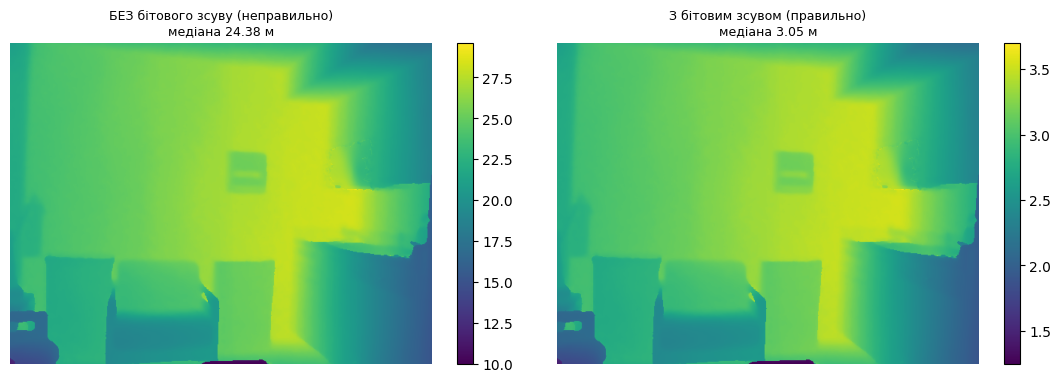

Орієнтир: для приміщення медіанна глибина має бути приблизно 1.5–4 м.


In [19]:
# демонстрація: що дає бітовий зсув
_demo = next(im for im in images if Path(im["depth_file"]).is_file())
_raw = np.array(Image.open(_demo["depth_file"]))
if _raw.ndim == 3:
    _raw = _raw[..., 0]
_wrong = _raw.astype(np.float32) / 1000.0          # без зсуву (неправильно)
_right = sd.decode_depth(_raw)                     # зі зсувом (правильно)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, data, title in (
    (axes[0], _wrong, "БЕЗ бітового зсуву (неправильно)"),
    (axes[1], _right, "З бітовим зсувом (правильно)"),
):
    m = np.ma.masked_where(data <= 0, data)
    im_ = ax.imshow(m, cmap="viridis")
    valid = data[data > 0]
    med = np.median(valid) if valid.size else 0
    ax.set_title(f"{title}\nмедіана {med:.2f} м", fontsize=9)
    ax.axis("off")
    fig.colorbar(im_, ax=ax, fraction=0.045)
plt.tight_layout(); plt.show()

print("Орієнтир: для приміщення медіанна глибина має бути приблизно 1.5–4 м.")

In [22]:
PALETTE = np.array([
    [230,25,75],[60,180,75],[255,225,25],[0,130,200],[245,130,48],[145,30,180],
    [70,240,240],[240,50,230],[210,245,60],[250,190,190],[0,128,128],[230,190,255],
    [170,110,40],[255,250,200],[128,0,0],[170,255,195],[128,128,0],[255,215,180],
], dtype=np.uint8)

cats_by_id = {c_["id"]: c_["name"] for c_ in coco["categories"]}
anns_by_img = defaultdict(list)
for a in annotations:
    anns_by_img[a["image_id"]].append(a)


def overlay_masks(rgb, masks, alpha=0.5):
    out = rgb.astype(np.float32).copy()
    for i, m in enumerate(masks):
        sel = m.astype(bool)
        out[sel] = (1 - alpha) * out[sel] + alpha * PALETTE[i % len(PALETTE)]
    return out.astype(np.uint8)


def inspect_scene(img_info, max_points=8000):
    """Будує оглядову панель для однієї сцени і повертає контрольні показники."""
    

    rgb = sd.read_rgb(Path(img_info["file_name"]))
    depth = sd.read_depth(Path(img_info["depth_file"]))
    h, w = rgb.shape[:2]
    if depth.shape[:2] != (h, w):
        depth = cv2.resize(depth, (w, h), interpolation=cv2.INTER_NEAREST)

    masks, labels = [], []
    for a in anns_by_img.get(img_info["id"], []):
        m = sd.polygons_to_mask(a["segmentation"], w, h)
        if m.any():
            masks.append(m); labels.append(cats_by_id[a["category_id"]])

    valid = depth > 0
    med = float(np.median(depth[valid])) if valid.any() else 0.0

    fig = plt.figure(figsize=(17, 4.3))
    ax1 = fig.add_subplot(1, 4, 1); ax1.imshow(rgb)
    ax1.set_title(f"RGB ({w}×{h}), {img_info['sensor']}", fontsize=9); ax1.axis("off")

    ax2 = fig.add_subplot(1, 4, 2); ax2.imshow(overlay_masks(rgb, masks))
    ax2.set_title(f"Маски: {len(masks)}\n{', '.join(sorted(set(labels))[:5])}", fontsize=8)
    ax2.axis("off")

    ax3 = fig.add_subplot(1, 4, 3)
    im_ = ax3.imshow(np.ma.masked_where(depth <= 0, depth), cmap="viridis")
    ax3.set_title(f"Глибина: медіана {med:.2f} м\nдостовірних {valid.mean():.0%}", fontsize=8)
    ax3.axis("off"); fig.colorbar(im_, ax=ax3, fraction=0.045)

    ax4 = fig.add_subplot(1, 4, 4, projection="3d")
    if img_info.get("fx"):
        intr = sd.Intrinsics(img_info["fx"], img_info["fy"], img_info["cx"], img_info["cy"])
        stride = max(1, int(np.sqrt(max(valid.sum(), 1) / max_points)))
        pts, cols = sd.backproject(depth, intr, rgb=rgb, stride=stride)
        if len(pts):
            ax4.scatter(pts[:,0], pts[:,2], -pts[:,1], c=cols, s=1.0, marker=".", linewidths=0)
            ax4.set_xlabel("X, м", fontsize=7); ax4.set_ylabel("Z, м", fontsize=7)
            ax4.set_zlabel("−Y, м", fontsize=7)
            ax4.view_init(elev=12, azim=-72); ax4.tick_params(labelsize=6)
            ax4.set_title("Контроль 3D-проєкції", fontsize=9)
    else:
        ax4.set_title("Немає параметрів камери", fontsize=9)

    fig.suptitle(img_info["rel_key"], fontsize=9)
    plt.tight_layout(); plt.show()

    return {"rel_key": img_info["rel_key"], "sensor": img_info["sensor"],
            "n_objects": len(masks), "depth_valid_ratio": round(float(valid.mean()), 3),
            "depth_median_m": round(med, 2)}

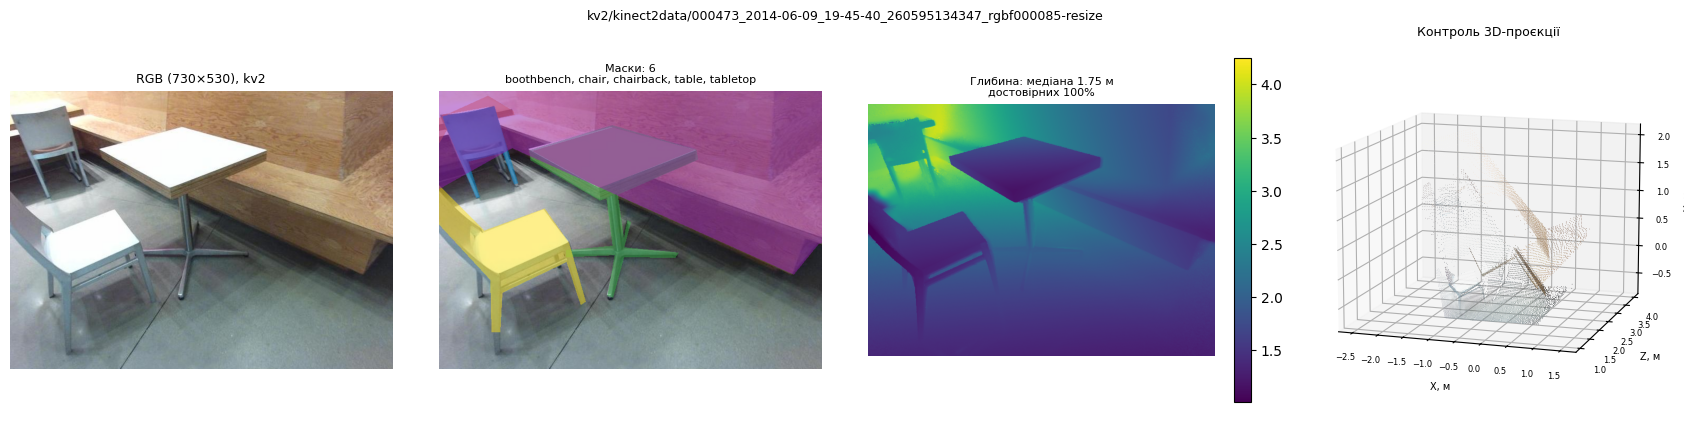

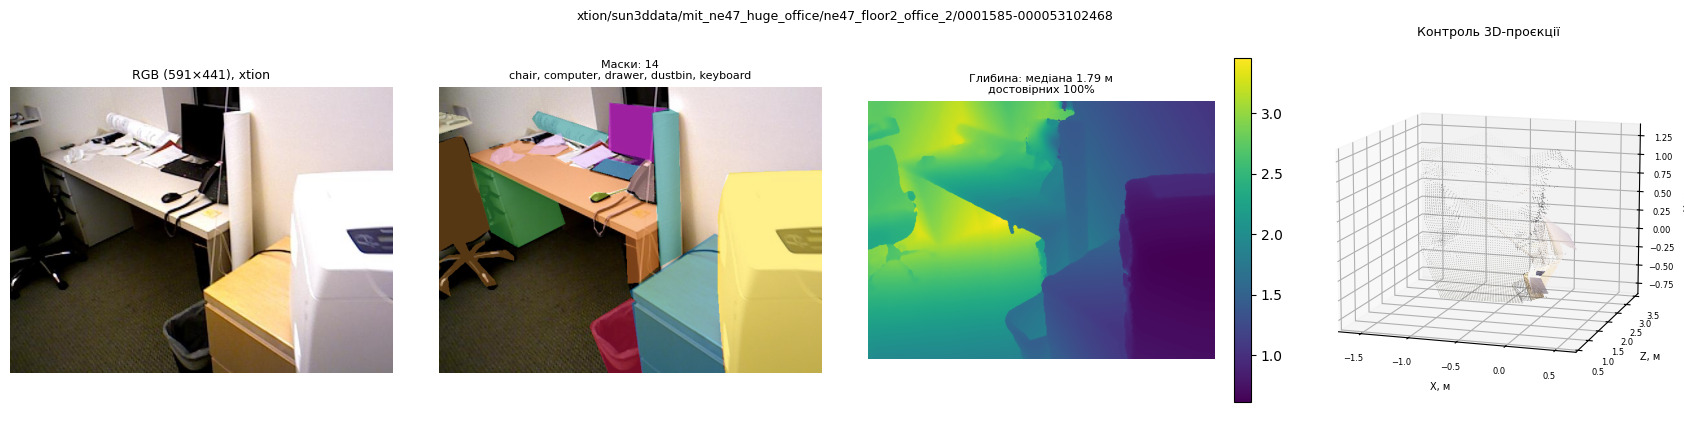

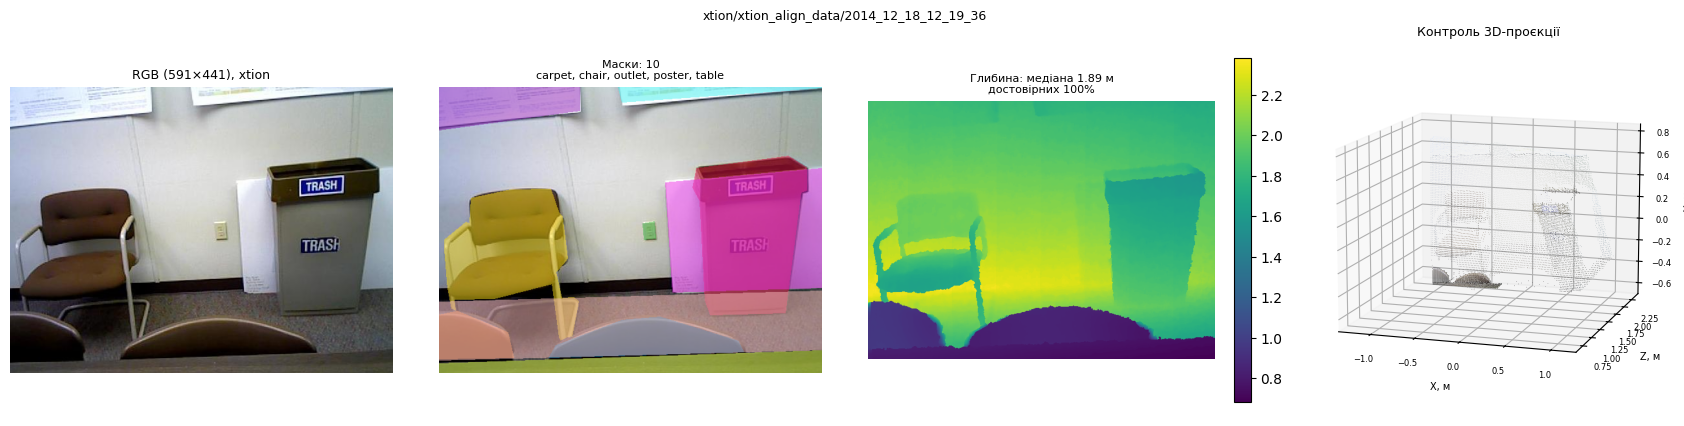

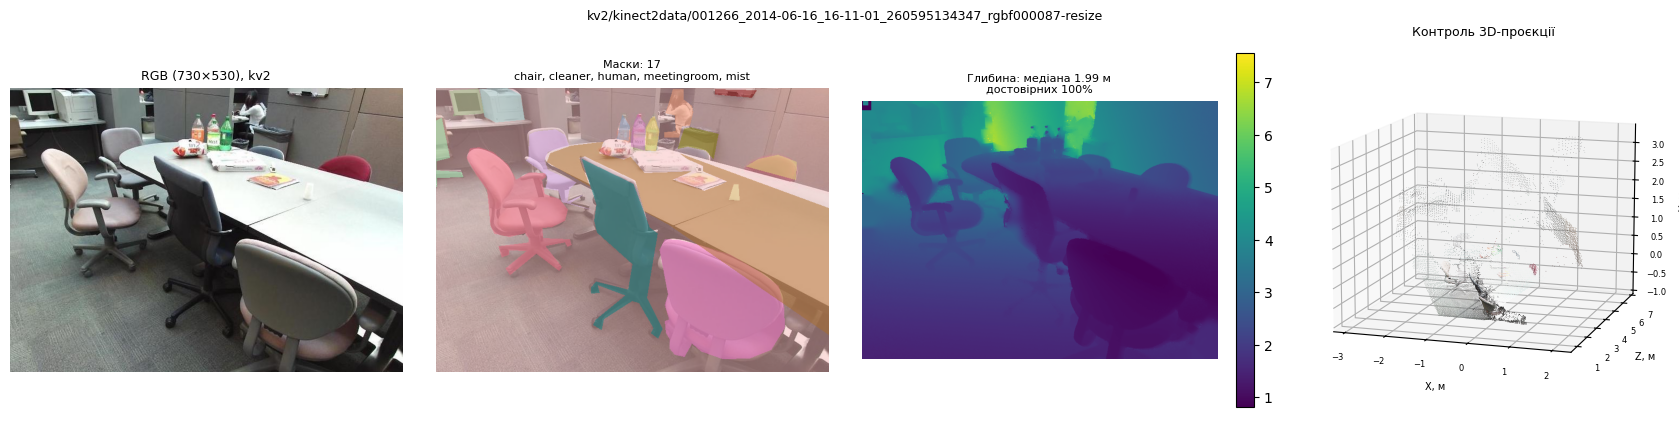

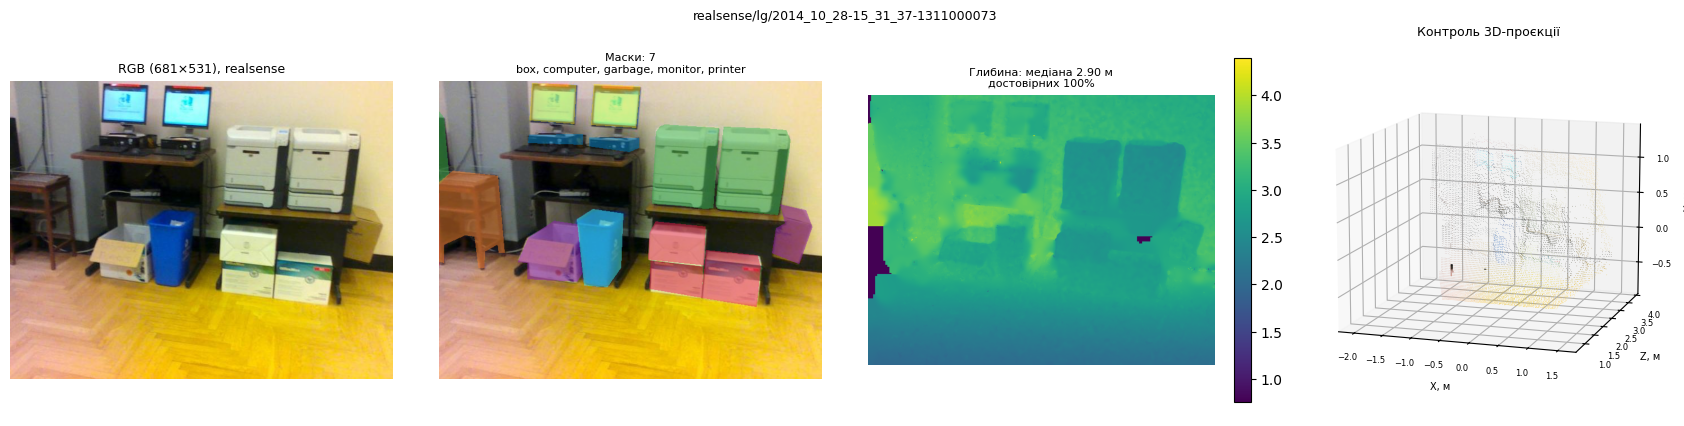

,rel_key,sensor,n_objects,depth_valid_ratio,depth_median_m
0,kv2/kinect2data/000473_2014-06-09_19-45-40_260...,kv2,6,1.0,1.75
1,xtion/sun3ddata/mit_ne47_huge_office/ne47_floo...,xtion,14,1.0,1.79
2,xtion/xtion_align_data/2014_12_18_12_19_36,xtion,10,1.0,1.89
3,kv2/kinect2data/001266_2014-06-16_16-11-01_260...,kv2,17,1.0,1.99
4,realsense/lg/2014_10_28-15_31_37-1311000073,realsense,7,1.0,2.90


Медіанна глибина по вибірці: 1.89 м


In [24]:
# перевіряємо випадкову вибірку сцен
N_CHECK = 5
sample = random.sample(images, min(N_CHECK, len(images)))
check_rows = [inspect_scene(im) for im in sample]

check_df = pd.DataFrame(check_rows)
display(check_df)
print(f"Медіанна глибина по вибірці: {check_df.depth_median_m.median():.2f} м")

### Окремий об'єкт у 3D

Перевіримо ключову операцію: зворотну проєкцію **окремої маски**
в тривимірний простір. Саме так формуватимуться хмари точок для кожного
сегментованого об'єкта.

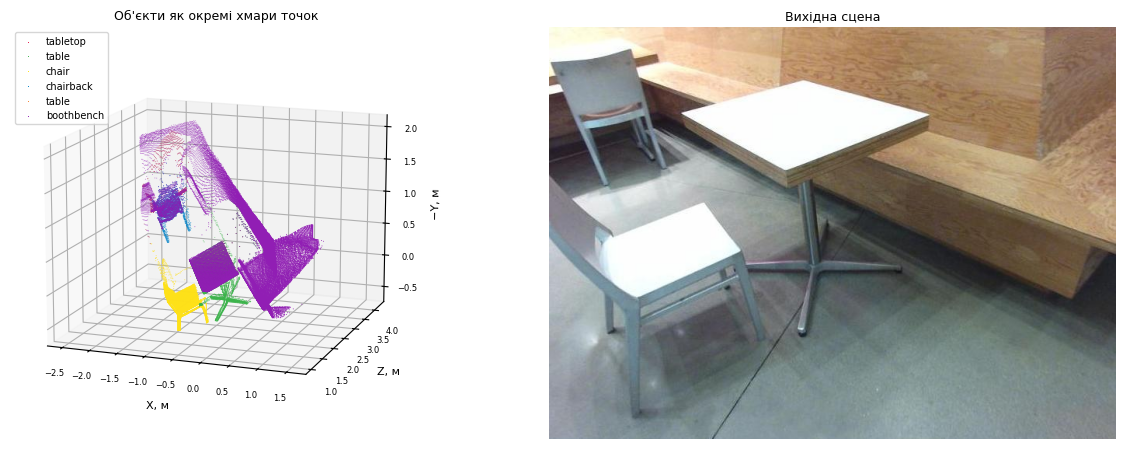

,Клас,Точок,"Відстань, м","Ширина, м","Висота, м","Глибина, м"
0,tabletop,4490,1.47,0.89,0.74,1.35
1,table,8304,1.51,1.81,1.45,2.56
2,chair,6855,1.42,1.93,1.07,2.18
3,chairback,2577,2.73,0.92,1.14,1.49
4,table,572,3.37,1.11,0.94,1.61
5,boothbench,40301,1.93,4.02,2.26,3.10


In [26]:
# беремо сцену з достатньою кількістю об'єктів
demo = next((im for im in sample if len(anns_by_img.get(im["id"], [])) >= 2 and im.get("fx")), None)

rgb = sd.read_rgb(Path(demo["file_name"]))
depth = sd.read_depth(Path(demo["depth_file"]))
h, w = rgb.shape[:2]
if depth.shape[:2] != (h, w):
    depth = cv2.resize(depth, (w, h), interpolation=cv2.INTER_NEAREST)
intr = sd.Intrinsics(demo["fx"], demo["fy"], demo["cx"], demo["cy"])

fig = plt.figure(figsize=(13, 4.6))
ax = fig.add_subplot(1, 2, 1, projection="3d")
stats = []
for i, a in enumerate(anns_by_img[demo["id"]][:6]):
    mask = sd.polygons_to_mask(a["segmentation"], w, h)
    pts, _ = sd.backproject(depth, intr, mask=mask, stride=2)
    if len(pts) < 30:
        continue
    color = PALETTE[i % len(PALETTE)] / 255.0
    ax.scatter(pts[:,0], pts[:,2], -pts[:,1], s=2, color=color,
               label=cats_by_id[a["category_id"]], marker=".", linewidths=0)
    size = pts.max(0) - pts.min(0)
    stats.append({
        "Клас": cats_by_id[a["category_id"]], "Точок": len(pts),
        "Відстань, м": round(float(np.median(pts[:,2])), 2),
        "Ширина, м": round(float(size[0]), 2),
        "Висота, м": round(float(size[1]), 2),
        "Глибина, м": round(float(size[2]), 2),
    })
ax.set_xlabel("X, м", fontsize=8); ax.set_ylabel("Z, м", fontsize=8)
ax.set_zlabel("−Y, м", fontsize=8)
ax.set_title("Об'єкти як окремі хмари точок", fontsize=9)
ax.legend(fontsize=7, loc="upper left"); ax.view_init(elev=14, azim=-70)
ax.tick_params(labelsize=6)

ax2 = fig.add_subplot(1, 2, 2); ax2.imshow(rgb); ax2.axis("off")
ax2.set_title("Вихідна сцена", fontsize=9)
plt.tight_layout(); plt.show()

display(pd.DataFrame(stats))

---
## Розвідувальний аналіз даних (EDA)

In [27]:
anns_df = pd.DataFrame([{
    "image_id": a["image_id"], "category": cats_by_id[a["category_id"]], "area": a["area"],
    "bbox_w": a["bbox"][2], "bbox_h": a["bbox"][3],
} for a in annotations])
imgs_df = pd.DataFrame(images)

per_cat = (anns_df.groupby("category")
           .agg(n_instances=("area", "size"), n_images=("image_id", "nunique"),
                median_area=("area", "median"))
           .sort_values("n_instances", ascending=False))
per_cat["share_%"] = (per_cat.n_instances / len(anns_df) * 100).round(2)
per_cat.to_csv(OUT_DIR / "class_distribution.csv")

print(f"Зображень: {len(imgs_df)}   Екземплярів: {len(anns_df)}   Категорій: {len(per_cat)}")
display(per_cat.head(20))

Зображень: 10294   Екземплярів: 126604   Категорій: 9466


,n_instances,n_images,median_area,share_%
category,,,,
chair,17274,5687,6743.0,13.64
table,9484,5612,13989.5,7.49
window,4015,2684,10673.0,3.17
book,3257,1330,1532.0,2.57
picture,3048,1383,1983.0,2.41
door,2975,2363,11149.0,2.35
pillow,2784,1221,3476.0,2.20
cabinet,2351,1358,11303.0,1.86
paper,2324,1427,1692.5,1.84


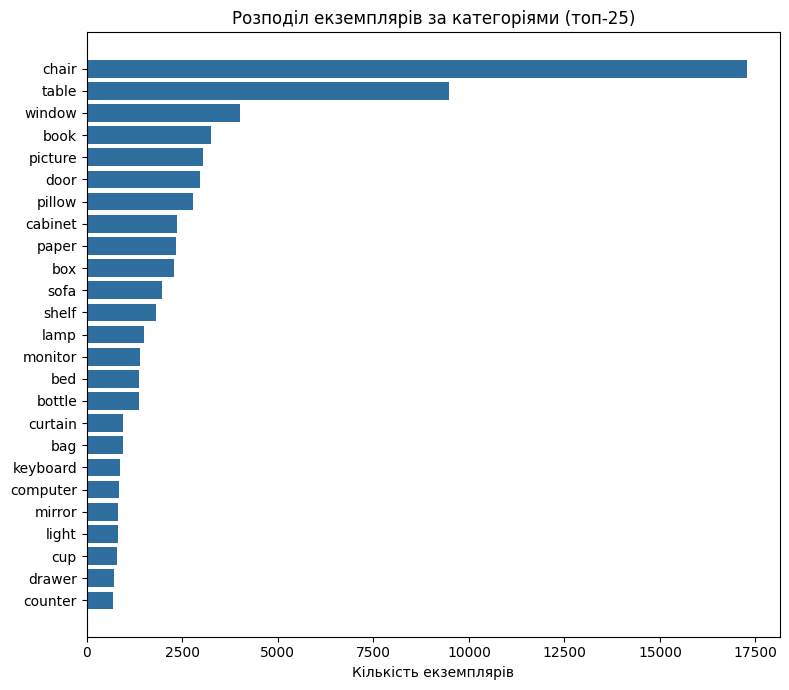

In [ ]:
# розподіл екземплярів за категоріями
top = per_cat.head(25).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, max(4, 0.28 * len(top))))
ax.barh(top.index, top.n_instances, color="#2f6f9f")
ax.set_xlabel("Кількість екземплярів")
ax.set_title("Розподіл екземплярів за категоріями (топ-25)")
plt.tight_layout(); plt.savefig(OUT_DIR / "class_distribution.png", bbox_inches="tight"); plt.show()

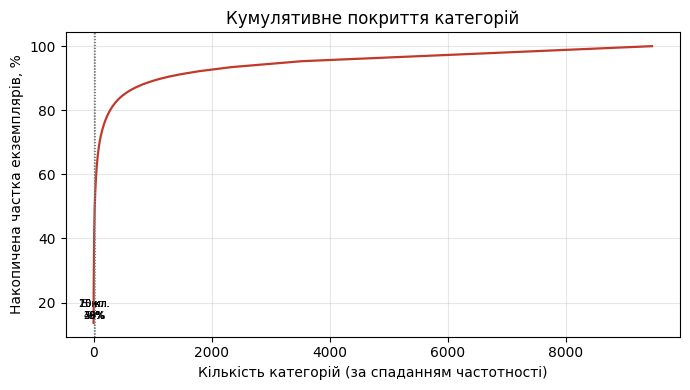

Топ-10 категорій покривають 39.3% усіх екземплярів.


In [32]:
# кумулятивне покриття — обґрунтування вибору топ-K класів (крок 1.6)
cum = per_cat.n_instances.cumsum() / per_cat.n_instances.sum() * 100
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(range(1, len(cum) + 1), cum.values, color="#c0392b", lw=1.6)
for k in (5, 10, 15, 20):
    if k <= len(cum):
        ax.axvline(k, ls=":", lw=0.8, color="grey")
        ax.text(k, 15, f"{k} кл.\n{cum.values[k-1]:.0f}%", fontsize=7, ha="center")
ax.set_xlabel("Кількість категорій (за спаданням частотності)")
ax.set_ylabel("Накопичена частка екземплярів, %")
ax.set_title("Кумулятивне покриття категорій"); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT_DIR / "class_cumulative_coverage.png", bbox_inches="tight"); plt.show()

print(f"Топ-{TOP_K_CLASSES} категорій покривають "
      f"{cum.values[min(TOP_K_CLASSES, len(cum)) - 1]:.1f}% усіх екземплярів.")

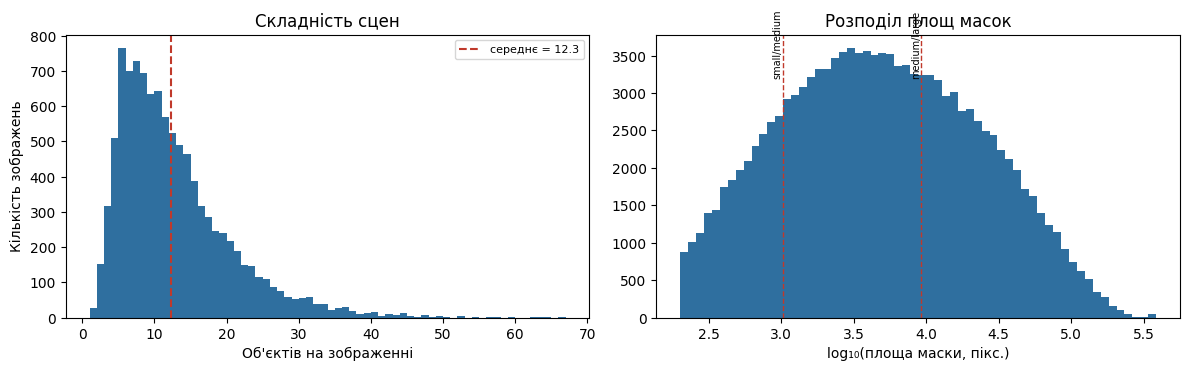

Градації розміру за критерієм COCO:


,n_instances,share_%
area,,
small,23395,18.5
medium,58481,46.2
large,44728,35.3


In [ ]:
# кількість об'єктів на зображення та розподіл площ масок
per_img = anns_df.groupby("image_id").size()

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(per_img.values, bins=range(1, int(per_img.max()) + 2), color="#2f6f9f")
axes[0].axvline(per_img.mean(), color="#c0392b", ls="--", label=f"середнє = {per_img.mean():.1f}")
axes[0].set_xlabel("Об'єктів на зображенні"); axes[0].set_ylabel("Кількість зображень")
axes[0].set_title("Складність сцен"); axes[0].legend(fontsize=8)

axes[1].hist(np.log10(np.clip(anns_df.area.values, 1, None)), bins=60, color="#2f6f9f")
for thr, lbl in ((32**2, "small/medium"), (96**2, "medium/large")):
    axes[1].axvline(np.log10(thr), color="#c0392b", ls="--", lw=1)
    axes[1].text(np.log10(thr), axes[1].get_ylim()[1]*0.85, lbl, fontsize=7, rotation=90, ha="right")
axes[1].set_xlabel("log₁₀(площа маски, пікс.)"); axes[1].set_title("Розподіл площ масок")
plt.tight_layout(); plt.savefig(OUT_DIR / "objects_and_areas.png", bbox_inches="tight"); plt.show()

size_bins = pd.cut(anns_df.area, [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
size_tbl = size_bins.value_counts().sort_index().to_frame("n_instances")
size_tbl["share_%"] = (size_tbl.n_instances / len(anns_df) * 100).round(1)
size_tbl.to_csv(OUT_DIR / "size_distribution.csv")
print("Градації розміру за критерієм COCO:"); display(size_tbl)

  200/200


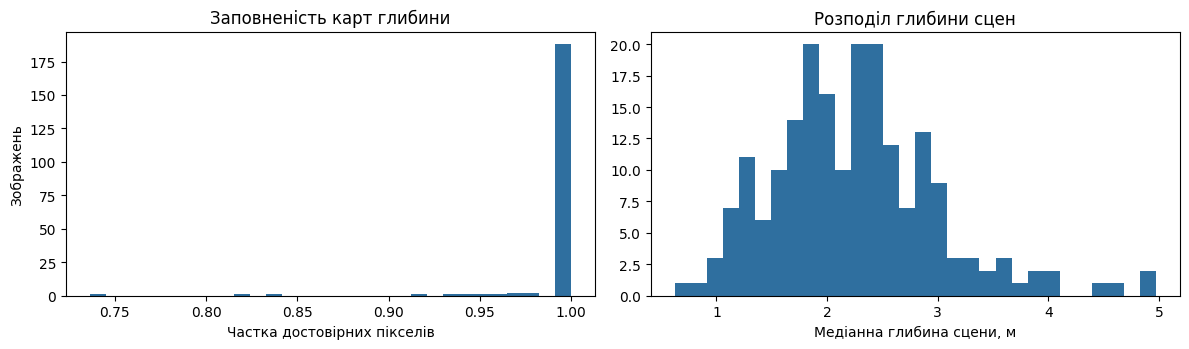

valid_ratio       median_m      
                 mean count     mean count
sensor                                    
kv1             1.000    45    2.209    45
kv2             1.000    69    2.254    69
realsense       1.000    20    1.982    20
xtion           0.985    66    2.364    66

In [ ]:
# якість карт глибини на підвибірці
DEPTH_SAMPLE = 200
sample_imgs = random.sample(images, min(DEPTH_SAMPLE, len(images)))
rows = []
for i, im in enumerate(sample_imgs, 1):
    if i % 50 == 0:
        print(f"  {i}/{len(sample_imgs)}", end="\r")
    p = Path(im["depth_file"])
    if not p.is_file():
        continue
    d = sd.read_depth(p); v = d > 0
    rows.append({"sensor": im["sensor"], "valid_ratio": float(v.mean()),
                 "median_m": float(np.median(d[v])) if v.any() else np.nan})
print()

depth_df = pd.DataFrame(rows)
depth_df.to_csv(OUT_DIR / "depth_stats_sample.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(depth_df.valid_ratio.dropna(), bins=30, color="#2f6f9f")
axes[0].set_xlabel("Частка достовірних пікселів"); axes[0].set_ylabel("Зображень")
axes[0].set_title("Заповненість карт глибини")
axes[1].hist(depth_df.median_m.dropna(), bins=30, color="#2f6f9f")
axes[1].set_xlabel("Медіанна глибина сцени, м"); axes[1].set_title("Розподіл глибини сцен")
plt.tight_layout(); plt.savefig(OUT_DIR / "depth_quality.png", bbox_inches="tight"); plt.show()

display(depth_df.groupby("sensor")[["valid_ratio", "median_m"]].agg(["mean", "count"]).round(3))

---
## Відбір цільових категорій

Замість усіх категорій залишаємо найчастотніші. Це підвищує якість навчання
(менше класів із поодинокими прикладами) і робить постановку задачі чіткішою.
Вибір обґрунтовується графіком кумулятивного покриття вище.

За потреби перелік можна задати вручну через змінну `MANUAL_CLASSES`.

In [33]:
# щоб задати класи вручну — впишіть їх сюди, напр. ["chair", "table", "sofa"]
MANUAL_CLASSES = []

keep_names = MANUAL_CLASSES or list(per_cat.head(TOP_K_CLASSES).index)
missing = [n for n in keep_names if n not in per_cat.index]
if missing:
    raise ValueError(f"Немає таких класів у даних: {missing}")

coverage = per_cat.loc[keep_names, "n_instances"].sum() / len(anns_df) * 100
print(f"Обрано категорій: {len(keep_names)}")
print(f"Покривають {coverage:.1f}% усіх анотованих екземплярів\n")
display(per_cat.loc[keep_names, ["n_instances", "n_images", "share_%"]])

Обрано категорій: 10
Покривають 39.3% усіх анотованих екземплярів



,n_instances,n_images,share_%
category,,,
chair,17274,5687,13.64
table,9484,5612,7.49
window,4015,2684,3.17
book,3257,1330,2.57
picture,3048,1383,2.41
door,2975,2363,2.35
pillow,2784,1221,2.20
cabinet,2351,1358,1.86
paper,2324,1427,1.84


In [34]:
# перенумеровуємо категорії з 1 (вимога COCO / Detectron2)
new_cats = [{"id": i, "name": n, "supercategory": "object"} for i, n in enumerate(keep_names, 1)]
name2new = {c_["name"]: c_["id"] for c_ in new_cats}

kept_anns = []
for a in annotations:
    name = cats_by_id[a["category_id"]]
    if name in name2new:
        b = dict(a); b["category_id"] = name2new[name]
        kept_anns.append(b)

MIN_OBJECTS_PER_IMAGE = 1
counts_per_img = Counter(a["image_id"] for a in kept_anns)
keep_ids = {i for i, n in counts_per_img.items() if n >= MIN_OBJECTS_PER_IMAGE}
kept_imgs = [im for im in images if im["id"] in keep_ids]
kept_anns = [a for a in kept_anns if a["image_id"] in keep_ids]

print(f"Після фільтрації: {len(kept_imgs)} зображень, {len(kept_anns)} екземплярів")

Після фільтрації: 9432 зображень, 49806 екземплярів


---
## Поділ на навчальну, валідаційну і тестову вибірки

Два принципові моменти:

**Поділ виконується по групах сцен, а не по окремих кадрах.** У колекції
`sun3ddata` багато кадрів знято з однієї кімнати послідовно. Якщо такі кадри
потраплять і в навчальну, і в тестову вибірку, оцінка якості буде **завищеною** —
модель фактично бачитиме тестові сцени під час навчання.

**Поділ детермінований.** Зерно генератора зафіксовано, а результат зберігається
у файл. Ділити випадково під час кожного запуску не можна: метрики різних
експериментів стануть непорівнюваними.

In [35]:
groups = defaultdict(list)
for im in kept_imgs:
    groups[im.get("group_key") or im["rel_key"]].append(im)

group_keys = sorted(groups)
rng = random.Random(SEED)
shuffled = list(group_keys); rng.shuffle(shuffled)

n = len(shuffled)
n_test, n_val = int(round(n * TEST_FRACTION)), int(round(n * VAL_FRACTION))
assign = {}
for i, g in enumerate(shuffled):
    assign[g] = "test" if i < n_test else ("val" if i < n_test + n_val else "train")

split_images = {"train": [], "val": [], "test": []}
for g, subset in assign.items():
    split_images[subset].extend(groups[g])

print(f"Груп сцен: {len(group_keys)}  →  "
      f"train {sum(1 for v in assign.values() if v=='train')}, "
      f"val {sum(1 for v in assign.values() if v=='val')}, "
      f"test {sum(1 for v in assign.values() if v=='test')}")

Груп сцен: 7350  →  train 5146, val 1102, test 1102


In [36]:
SPLIT_DIR = OUT_DIR / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

summary, dist_rows = [], []
for subset, imgs in split_images.items():
    ids = {im["id"] for im in imgs}
    sub_anns = [a for a in kept_anns if a["image_id"] in ids]
    out = {"info": {**coco.get("info", {}), "subset": subset}, "licenses": [],
           "images": imgs, "annotations": sub_anns, "categories": new_cats}
    (SPLIT_DIR / f"instances_{subset}.json").write_text(json.dumps(out), encoding="utf-8")

    summary.append({"Вибірка": subset, "Зображень": len(imgs), "Екземплярів": len(sub_anns),
                    "Частка, %": round(len(imgs) / len(kept_imgs) * 100, 1)})
    cc = Counter(a["category_id"] for a in sub_anns)
    for c_ in new_cats:
        dist_rows.append({"subset": subset, "category": c_["name"],
                          "n_instances": cc.get(c_["id"], 0)})

display(pd.DataFrame(summary))

dist = (pd.DataFrame(dist_rows).pivot(index="category", columns="subset", values="n_instances")
        .fillna(0).astype(int))
dist = dist[[c_ for c_ in ("train", "val", "test") if c_ in dist.columns]]
dist["total"] = dist.sum(axis=1)
dist = dist.sort_values("total", ascending=False)
dist.to_csv(SPLIT_DIR / "split_class_distribution.csv")
print("\nРозподіл екземплярів за класами:"); display(dist)

,Вибірка,Зображень,Екземплярів,"Частка, %"
0,train,6482,34362,68.7
1,val,1402,7387,14.9
2,test,1548,8057,16.4



Розподіл екземплярів за класами:


subset,train,val,test,total
category,,,,
chair,11991,2502,2781,17274
table,6597,1412,1475,9484
window,2808,612,595,4015
book,2116,549,592,3257
picture,2089,429,530,3048
door,2039,429,507,2975
pillow,1839,448,497,2784
cabinet,1670,333,348,2351
paper,1608,344,372,2324


In [37]:
# контроль: чи немає витоку між вибірками
seen, leaks = {}, set()
for subset, imgs in split_images.items():
    for im in imgs:
        g = im.get("group_key", "")
        if g in seen and seen[g] != subset:
            leaks.add(g)
        seen[g] = subset

if leaks:
    print(f"УВАГА: {len(leaks)} груп потрапили в різні вибірки!")
else:
    print("Витоку немає: кожна група сцен належить лише одній вибірці.")

# фіксуємо поділ у файл — щоб його можна було відтворити
pd.DataFrame([
    {"rel_key": im["rel_key"], "image_id": im["id"], "group_key": im.get("group_key", ""),
     "subset": subset, "sensor": im["sensor"]}
    for subset, imgs in split_images.items() for im in imgs
]).sort_values(["subset", "rel_key"]).to_csv(SPLIT_DIR / "split_assignment.csv", index=False)
print(f"Поділ збережено: {SPLIT_DIR / 'split_assignment.csv'}")

Витоку немає: кожна група сцен належить лише одній вибірці.
Поділ збережено: outputs/splits/split_assignment.csv


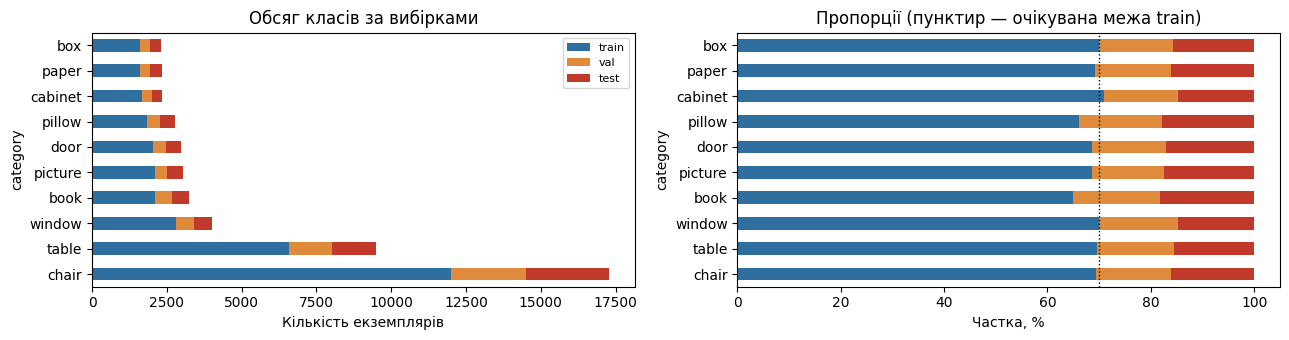

In [ ]:
# візуальний контроль збалансованості вибірок
share = dist[[c_ for c_ in ("train","val","test") if c_ in dist.columns]]
share = share.div(share.sum(axis=1), axis=0) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, max(3.5, 0.32*len(dist))))
dist[[c_ for c_ in ("train","val","test") if c_ in dist.columns]].plot.barh(
    stacked=True, ax=axes[0], color=["#2f6f9f", "#e08b3c", "#c0392b"])
axes[0].set_xlabel("Кількість екземплярів"); axes[0].set_title("Обсяг класів за вибірками")
axes[0].legend(fontsize=8)

share.plot.barh(stacked=True, ax=axes[1], color=["#2f6f9f", "#e08b3c", "#c0392b"], legend=False)
axes[1].axvline(100*(1-VAL_FRACTION-TEST_FRACTION), color="k", ls=":", lw=1)
axes[1].set_xlabel("Частка, %"); axes[1].set_title("Пропорції (пунктир - очікувана межа train)")
plt.tight_layout(); plt.savefig(OUT_DIR / "split_balance.png", bbox_inches="tight"); plt.show()

---
## Підсумок

Підготовлено файли для навчання моделі:

* `outputs/splits/instances_train.json`
* `outputs/splits/instances_val.json`
* `outputs/splits/instances_test.json`

Кожне зображення містить також поля `depth_file`, `fx`, `fy`, `cx`, `cy` —
вони знадобляться для побудови хмар точок.

### Матеріали

| Файл | Призначення |
|---|---|
| `class_distribution.png` | розподіл екземплярів за категоріями |
| `class_cumulative_coverage.png` | обґрунтування вибору цільових класів |
| `objects_and_areas.png` | складність сцен і розподіл площ масок |
| `depth_quality.png` | достовірність карт глибини |
| `split_balance.png` | збалансованість вибірок |
| `splits/split_class_distribution.csv` | таблиця обсягів вибірок |
| `name_normalization_map.csv` | нормалізація назв категорій |